# Walkthrough 1: Black-Scholes prices and Greeks

This notebook explains `src/quantcore/black_scholes.py`: the idea first, then the formulas, then the code, then how we know it is right. Read it with the source file open beside it.

**After this you should be able to:**

1. Say in two sentences where the Black-Scholes formula comes from.
2. Write the call and put formulas from memory and say what $N(d_1)$ and $N(d_2)$ mean.
3. Explain each Greek: what it measures, its sign, and its units.
4. Name four ways the model is wrong.

## 1. Conventions

The same names and units are used everywhere in the package.

| Name in code | Symbol | Meaning | Unit |
|---|---|---|---|
| `spot` | $S$ | price of the underlying now | money |
| `strike` | $K$ | strike price | money |
| `time` | $T$ | time to expiry | **years** (days / 365) |
| `vol` | $\sigma$ | annualised volatility | decimal: 0.64 is 64% |
| `rate` | $r$ | risk-free rate, continuously compounded | decimal |
| `div_yield` | $q$ | dividend yield, continuously compounded | decimal |
| `kind` | | `"call"` or `"put"` | |

$N(x)$ is the standard normal cumulative distribution (`ndtr` in the code) and $\varphi(x)$ is its density.

## 2. Where the formula comes from

**Step 1: how the price moves.** Assume the stock follows a geometric Brownian motion with constant volatility $\sigma$. Then the price at expiry is lognormal. For pricing we use the *risk-neutral* version, in which the stock grows at the risk-free rate less dividends:

$$S_T = S\,\exp\!\Big(\big(r-q-\tfrac12\sigma^2\big)T+\sigma\sqrt{T}\,Z\Big),\qquad Z\sim N(0,1)$$

The $-\tfrac12\sigma^2$ is there so that the *average* of $S_T$ equals the forward price $S e^{(r-q)T}$.

**Step 2: value is the discounted expected payoff.**

$$C = e^{-rT}\,E\big[\max(S_T-K,\,0)\big] = e^{-rT}\Big(E\big[S_T\,\mathbf 1_{S_T>K}\big]-K\,P(S_T>K)\Big)$$

**Step 3: work out the two pieces.** The call finishes in the money exactly when $Z>-d_2$, so $P(S_T>K)=N(d_2)$. The other piece works out to $S e^{(r-q)T}N(d_1)$. Together:

$$\boxed{\,C = S e^{-qT}N(d_1)-K e^{-rT}N(d_2)\,}$$

$$d_1=\frac{\ln(S/K)+\big(r-q+\tfrac12\sigma^2\big)T}{\sigma\sqrt T},\qquad d_2=d_1-\sigma\sqrt T$$

**The put** follows from put-call parity, $C-P=S e^{-qT}-K e^{-rT}$:

$$P = K e^{-rT}N(-d_2)-S e^{-qT}N(-d_1)$$

**How to read it**

- $N(d_2)$ is the risk-neutral probability that the call finishes in the money. $K e^{-rT}N(d_2)$ is the present value of paying the strike, weighted by that probability.
- $S e^{-qT}N(d_1)$ is the present value of receiving the stock when the call is exercised. $N(d_1)\ge N(d_2)$ because in the cases where the call is exercised the stock is worth more than usual.
- These are *risk-neutral* probabilities. They assume the stock drifts at $r-q$, not at its true expected return, so they are pricing weights, not forecasts. This matters later for the "chance of profit" number.

In [1]:
import numpy as np
from scipy.special import ndtr

from quantcore import black_scholes as bs

# Hull's standard worked example
S, K, T, sigma, r = 42.0, 40.0, 0.5, 0.20, 0.10

d1, d2 = bs.d1_d2(S, K, T, sigma, r)
print(f"d1 = {float(d1):.4f}    d2 = {float(d2):.4f}")
print(f"call = {float(bs.price(S, K, T, sigma, r, kind='call')):.4f}   (textbook: 4.76)")
print(f"put  = {float(bs.price(S, K, T, sigma, r, kind='put')):.4f}   (textbook: 0.81)")

d1 = 0.7693    d2 = 0.6278
call = 4.7594   (textbook: 4.76)
put  = 0.8086   (textbook: 0.81)


## 3. The code, piece by piece

### `d1_d2`

In [2]:
import inspect

print(inspect.getsource(bs.d1_d2))

def d1_d2(spot, strike, time, vol, rate=0.0, div_yield=0.0):
    """The two numbers every Black-Scholes formula is built from.

        d1 = [ln(S/K) + (r - q + sigma^2 / 2) T] / (sigma sqrt(T))
        d2 = d1 - sigma sqrt(T)

    N(d2) is the risk-neutral probability that a call finishes in the money.

    When no randomness is left (expiry has arrived, or volatility is zero) the
    option is certain to finish in or out of the money, so d1 and d2 are
    +infinity or -infinity. That makes N(d) exactly 1 or 0 and the price
    formulas below collapse to intrinsic value without a special case.
    """
    spot, strike, time, vol, rate, div_yield = _inputs(spot, strike, time, vol, rate, div_yield)
    total_vol = vol * np.sqrt(time)  # sigma sqrt(T)
    log_forward_moneyness = np.log(spot / strike) + (rate - div_yield) * time  # ln(F/K)
    with np.errstate(divide="ignore", invalid="ignore"):
        d1 = log_forward_moneyness / total_vol + 0.5 * total_vol
    certain = np.where(
     

What to notice:

- `total_vol` is $\sigma\sqrt T$, the standard deviation of the log price over the option's life. It appears in every formula, so it gets a name.
- `log_forward_moneyness` is $\ln(F/K)$ where $F=S e^{(r-q)T}$ is the forward. Writing $d_1=\ln(F/K)/\sigma\sqrt T+\tfrac12\sigma\sqrt T$ is the same formula as above, rearranged.
- **The edge case.** At expiry, or with zero volatility, $\sigma\sqrt T=0$ and the division would fail. But with no randomness left the outcome is certain: the option finishes in the money or it does not. So $d_1$ is set to $+\infty$ or $-\infty$, which makes $N(d)$ exactly 1 or 0, and the price formula then gives intrinsic value with no special case of its own.
- `np.where` and friends make everything work on arrays, so one call can fill a whole grid.

### `price`

In [3]:
print(inspect.getsource(bs.price))

def price(spot, strike, time, vol, rate=0.0, div_yield=0.0, kind="call"):
    """Black-Scholes-Merton value of a European option, per share.

        call = S e^(-qT) N(d1)  - K e^(-rT) N(d2)
        put  = K e^(-rT) N(-d2) - S e^(-qT) N(-d1)

    Both lines are the same expression with a sign flipped, which is how the
    code below is written.
    """
    sign = _sign(kind)
    d1, d2 = d1_d2(spot, strike, time, vol, rate, div_yield)
    spot, strike, time, vol, rate, div_yield = _inputs(spot, strike, time, vol, rate, div_yield)
    value = sign * (
        spot * np.exp(-div_yield * time) * ndtr(sign * d1)
        - strike * np.exp(-rate * time) * ndtr(sign * d2)
    )
    # Rounding can leave a far out-of-the-money option at -1e-17. A price is never negative.
    return np.maximum(value, 0.0)



The call and put formulas are the same expression with signs flipped, so the code uses `sign = +1` for a call and `-1` for a put:

$$\text{value}=\text{sign}\cdot\Big(S e^{-qT}N(\text{sign}\cdot d_1)-K e^{-rT}N(\text{sign}\cdot d_2)\Big)$$

### An independent check: simulate it

If the formula really is "discounted expected payoff under the lognormal distribution", then simulating that distribution must give the same number. It also lets us see $N(d_2)$ as a probability.

In [4]:
rng = np.random.default_rng(0)
Z = rng.standard_normal(2_000_000)
S_T = S * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)

payoff = np.maximum(S_T - K, 0.0)
estimate = np.exp(-r * T) * payoff.mean()
margin = 1.96 * np.exp(-r * T) * payoff.std() / np.sqrt(len(Z))

print(f"simulated call value: {estimate:.4f} +/- {margin:.4f}")
print(f"formula:              {float(bs.price(S, K, T, sigma, r)):.4f}")
print()
print(f"share of paths finishing in the money: {(S_T > K).mean():.4f}")
print(f"N(d2):                                 {float(ndtr(d2)):.4f}")

simulated call value: 4.7631 +/- 0.0069
formula:              4.7594

share of paths finishing in the money: 0.7351
N(d2):                                 0.7349


## 4. The Greeks

A Greek is the sensitivity of the option's value to one input, holding the others fixed.

| Greek | Formula (call) | What it tells you | Unit in the code |
|---|---|---|---|
| delta | $e^{-qT}N(d_1)$ | value change per +1 in spot. Also the hedge ratio. | per 1.00 of spot |
| gamma | $\dfrac{e^{-qT}\varphi(d_1)}{S\sigma\sqrt T}$ | how fast delta changes. Largest at the money, near expiry. | per 1.00 of spot |
| vega | $S e^{-qT}\varphi(d_1)\sqrt T$ | value change per unit of volatility | per 1.00 of vol. Divide by 100 for one point. |
| theta | $-\dfrac{S e^{-qT}\varphi(d_1)\sigma}{2\sqrt T}-rKe^{-rT}N(d_2)+qSe^{-qT}N(d_1)$ | value change as time passes | per **year**. Divide by 365 for one day. |
| rho | $KTe^{-rT}N(d_2)$ | value change per unit of interest rate | per 1.00 of rate. Divide by 100 for 1%. |

For a put: delta is $-e^{-qT}N(-d_1)$, gamma and vega are identical to the call's, and theta and rho flip the sign on their $N(\cdot)$ terms.

The honest test of a Greek is "bump and reprice": move the input a tiny amount, reprice, and divide. The formula and the bump must agree.

In [5]:
g = bs.greeks(S, K, T, sigma, r)
h = 1e-4

bump_and_reprice = {
    "delta": (bs.price(S + h, K, T, sigma, r) - bs.price(S - h, K, T, sigma, r)) / (2 * h),
    "gamma": (bs.delta(S + h, K, T, sigma, r) - bs.delta(S - h, K, T, sigma, r)) / (2 * h),
    "vega": (bs.price(S, K, T, sigma + h, r) - bs.price(S, K, T, sigma - h, r)) / (2 * h),
    "theta": -(bs.price(S, K, T + h, sigma, r) - bs.price(S, K, T - h, sigma, r)) / (2 * h),
    "rho": (bs.price(S, K, T, sigma, r + h) - bs.price(S, K, T, sigma, r - h)) / (2 * h),
}

for name, numeric in bump_and_reprice.items():
    print(f"{name:6s} formula {float(getattr(g, name)):10.5f}    bump and reprice {float(numeric):10.5f}")

print()
print(f"in everyday units: theta {float(g.theta_per_day):.4f} per day, vega {float(g.vega_per_point):.4f} per volatility point")

delta  formula    0.77913    bump and reprice    0.77913


gamma  formula    0.04996    bump and reprice    0.04996
vega   formula    8.81342    bump and reprice    8.81341
theta  formula   -4.55909    bump and reprice   -4.55909
rho    formula   13.98205    bump and reprice   13.98205

in everyday units: theta -0.0125 per day, vega 0.0881 per volatility point


Things interviewers like to probe:

- **Theta's minus sign.** Theta is the change as *calendar time passes*, which means time to expiry *shrinking*. That is why the bump above has a minus in front.
- **Gamma and theta are two sides of one trade.** A long option has positive gamma (it gains from movement) and pays for it with negative theta (it loses from waiting).
- **Call delta minus put delta is $e^{-qT}$**, which is put-call parity differentiated once.
- **Vega is the same for a call and a put** with the same strike and expiry, again because of parity: the difference between them does not depend on volatility.

The pictures below use the position from the options tool: strike 180, 64% volatility.

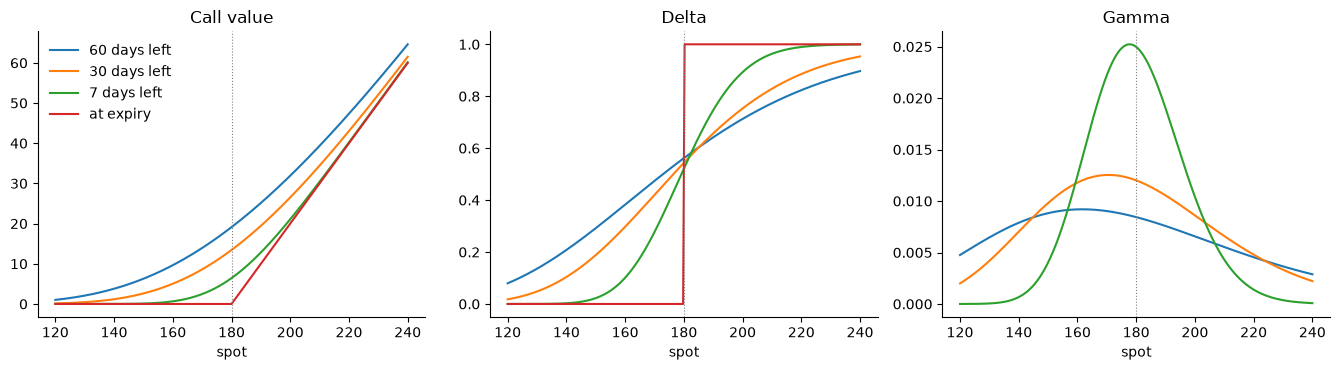

In [6]:
import matplotlib.pyplot as plt

spots = np.linspace(120, 240, 481)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

for days in (60, 30, 7, 0):
    t = days / 365
    label = "at expiry" if days == 0 else f"{days} days left"
    axes[0].plot(spots, bs.price(spots, 180, t, 0.64, 0.04), label=label)
    axes[1].plot(spots, bs.delta(spots, 180, t, 0.64, 0.04), label=label)
    if days:
        axes[2].plot(spots, bs.gamma(spots, 180, t, 0.64, 0.04), label=label)

for ax, title in zip(axes, ("Call value", "Delta", "Gamma")):
    ax.set_title(title)
    ax.set_xlabel("spot")
    ax.axvline(180, color="grey", linewidth=0.8, linestyle=":")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

Read the three panels together: as expiry approaches, the value curve collapses onto the hockey stick, delta sharpens into a step at the strike, and gamma piles up at the strike.

## 5. Edge cases

At expiry and at zero volatility the general formulas divide by zero. The `certain` trick in `d1_d2` handles both.

In [7]:
print("d1 at expiry, spot below / at / above the strike:", bs.d1_d2(np.array([170.0, 180.0, 190.0]), 180.0, 0.0, 0.64)[0])
print("call at expiry:", bs.price(np.array([170.0, 180.0, 190.0]), 180.0, 0.0, 0.64, kind="call"))
print("put at expiry: ", bs.price(np.array([170.0, 180.0, 190.0]), 180.0, 0.0, 0.64, kind="put"))
print("gamma at expiry:", bs.gamma(np.array([170.0, 180.0, 190.0]), 180.0, 0.0, 0.64), " (by convention; the true value at the strike is infinite)")

d1 at expiry, spot below / at / above the strike: [-inf   0.  inf]
call at expiry: [ 0.  0. 10.]
put at expiry:  [10.  0.  0.]
gamma at expiry: [0. 0. 0.]  (by convention; the true value at the strike is infinite)


## 6. How we know it is right

`tests/test_black_scholes.py` checks, on hundreds of random inputs:

- the textbook values above,
- put-call parity and the no-arbitrage bounds,
- every Greek against bump-and-reprice,
- the edge cases.

`tests/test_quantlib_crosscheck.py` then compares the price and all five Greeks with **QuantLib**, the open-source library used across the industry, on 1,536 combinations of inputs. Every one agrees to within 0.000001. One comparison by hand:

In [8]:
try:
    import QuantLib as ql
except ImportError:
    print("QuantLib is not installed. Run: pip install QuantLib")
else:
    today = ql.Date(16, 11, 2026)
    ql.Settings.instance().evaluationDate = today
    day_count = ql.Actual365Fixed()
    spot, strike, days, vol, rate = 166.0, 180.0, 30, 0.64, 0.04

    option = ql.VanillaOption(ql.PlainVanillaPayoff(ql.Option.Call, strike), ql.EuropeanExercise(today + days))
    process = ql.BlackScholesMertonProcess(
        ql.QuoteHandle(ql.SimpleQuote(spot)),
        ql.YieldTermStructureHandle(ql.FlatForward(today, 0.0, day_count)),
        ql.YieldTermStructureHandle(ql.FlatForward(today, rate, day_count)),
        ql.BlackVolTermStructureHandle(ql.BlackConstantVol(today, ql.NullCalendar(), vol, day_count)),
    )
    option.setPricingEngine(ql.AnalyticEuropeanEngine(process))

    ours = bs.greeks(spot, strike, days / 365, vol, rate)
    print(f"price  ours {float(bs.price(spot, strike, days / 365, vol, rate)):.8f}   QuantLib {option.NPV():.8f}")
    print(f"delta  ours {float(ours.delta):.8f}   QuantLib {option.delta():.8f}")
    print(f"gamma  ours {float(ours.gamma):.8f}   QuantLib {option.gamma():.8f}")
    print(f"vega   ours {float(ours.vega):.8f}  QuantLib {option.vega():.8f}")
    print(f"theta  ours {float(ours.theta):.8f} QuantLib {option.theta():.8f}")

price  ours 7.03044493   QuantLib 7.03044493
delta  ours 0.37008375   QuantLib 0.37008375
gamma  ours 0.01239727   QuantLib 0.01239727
vega   ours 17.97010482  QuantLib 17.97010482
theta  ours -72.13974645 QuantLib -72.13974645


## 7. Where this model is wrong

Knowing the limits is part of knowing the model.

1. **Volatility is not constant.** Real option prices imply a different volatility for every strike and expiry (the smile and the term structure). Black-Scholes is used as a quoting convention, one volatility per option, not as a belief that one number fits all.
2. **Early exercise.** The formula is for European options. US stock options are American and can be exercised early, which matters for puts and for calls just before a dividend.
3. **Dividends are discrete.** A continuous yield $q$ is a convenience. Real stocks pay lumps on known dates.
4. **Prices jump.** Earnings and news move prices in gaps, which the lognormal model has no room for. This is the reason implied volatility is high before earnings and collapses after, the subject of a later module.
5. **Rates, costs and liquidity.** The model assumes a constant rate, free trading and continuous hedging.

## 8. Your turn

1. Open `exercises/black_scholes.py` and fill in the seven functions from the formulas in this notebook, without looking at the engine's source.
2. Run `pytest exercises -m "not edge"` until the twelve core tests pass.
3. Then handle the edge cases and run `pytest exercises` for all twenty.

**Questions I will ask you afterwards**

1. Starting from the lognormal distribution of $S_T$, where do the two terms of the call formula come from?
2. What do $N(d_1)$ and $N(d_2)$ each mean, and why is $N(d_1)\ge N(d_2)$?
3. A call is deep in the money one day before expiry. Roughly what are its delta, gamma and vega, and why?
4. Theta of a long option is usually negative. When can a European put have positive theta?
5. A tool reports "chance of profit 23%". Which probability is that exactly, and why is it not the real-world chance?